In [1]:
import os
import re
import fnmatch
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
from concurrent.futures import ProcessPoolExecutor, ThreadPoolExecutor
from procompa import get_project_root

PRJ_ROOT = get_project_root()
data_dir = PRJ_ROOT / "data"

In [2]:
%config InlineBackend.figure_format = "retina"

# Mean and median pLDDT of the CombFold input pair models

Per pair model, computes the mean and median Cα pLDDT over both chains, and the lower of the two per-chain medians.
CombFold superimposes each chain using residues with pLDDT ≥ min(80, median of that chain), so `min_chain_median_plddt` < 80 marks pair models where the superposition cutoff falls below 80.

In [3]:
PIPE = data_dir / "Pipeline"

# set name -> (CombFold base dir, subdir inside each *_pool_input)
SET_DIRS = {
    "ranking":               (PIPE / "10_all_CP_complexes/CombFold", "pdbs"),
    "pae":                   (PIPE / "18_CP_model_based_on_pae/CombFold", "pdbs"),
    "pae_trimmed":           (PIPE / "19_CP_pae_plddt_trimmed/CombFold", "pdbs"),
    "pae_trimmed_safeguard": (PIPE / "20_CP_pae_plddt_trimmed_interface_safeguard/CombFold", "pdbs"),
}
SETS = list(SET_DIRS)
PLOT_ORDER = ["ranking", "pae", "pae_trimmed_safeguard", "pae_trimmed"]
COLORS = dict(zip(SETS, ["#9e9e9e", "#2ca02c", "#1f77b4", "#ff7f0e"]))
PDB_GLOB = "AFM_*_unrelaxed_rank_1_*.pdb"
CF_SUPERPOSITION_CUTOFF = 80

PLDDT_CSV = "./plddt_mean_median_per_pair.csv"

METRICS = [
    ("mean_plddt", "Mean pLDDT"),
    ("median_plddt", "Median pLDDT"),
    ("min_chain_median_plddt", "Lower median pLDDT of the two chains"),
]
MEDIAN_METRICS = {"median_plddt", "min_chain_median_plddt"}

assert sorted(PLOT_ORDER) == sorted(SETS), f"PLOT_ORDER {PLOT_ORDER} does not match SETS {SETS}"
for set_name, (base_dir, _) in SET_DIRS.items():
    assert base_dir.is_dir(), f"{set_name}: {base_dir} does not exist"

In [4]:
# %% file discovery: parallel scandir over pool dirs
def list_pool_dir(pdb_dir):
    """Sorted matching pdb names in one dir; [] if the subdir does not exist."""
    try:
        with os.scandir(pdb_dir) as entries:
            return pdb_dir, sorted(e.name for e in entries if fnmatch.fnmatchcase(e.name, PDB_GLOB))
    except FileNotFoundError:
        return pdb_dir, []


def find_pairs(base_dir, subdir, n_threads=32):
    """One pdb path per unique pair (first occurrence over sorted pool dirs)."""
    with os.scandir(base_dir) as entries:
        pool_dirs = sorted(e.path for e in entries if e.is_dir() and e.name.endswith("_pool_input"))
    assert len(pool_dirs) > 0, f"no *_pool_input dirs in {base_dir}"
    with ThreadPoolExecutor(max_workers=n_threads) as executor:
        listings = list(executor.map(list_pool_dir, (os.path.join(p, subdir) for p in pool_dirs)))
    pdb_path_by_pair = {}
    for pdb_dir, pdb_names in listings:  # map keeps sorted order -> deterministic
        for pdb_name in pdb_names:
            pair = pdb_name.removeprefix("AFM_").split("_unrelaxed")[0]
            pdb_path_by_pair.setdefault(pair, os.path.join(pdb_dir, pdb_name))
    assert len(pdb_path_by_pair) > 0, f"no pdbs found in {base_dir}/*_pool_input/{subdir}"
    return pdb_path_by_pair


pdb_paths_by_set = {s: find_pairs(base_dir, subdir) for s, (base_dir, subdir) in SET_DIRS.items()}
for set_name, pdb_path_by_pair in pdb_paths_by_set.items():
    print(f"{set_name:>22}: {len(pdb_path_by_pair)} pairs")

               ranking: 8851 pairs
                   pae: 6839 pairs
           pae_trimmed: 6837 pairs
 pae_trimmed_safeguard: 6838 pairs


In [5]:
# %% restrict to pairs present in all sets (only these are parsed)
common_pairs = set.intersection(*(set(p) for p in pdb_paths_by_set.values()))
all_pairs = set.union(*(set(p) for p in pdb_paths_by_set.values()))
assert len(common_pairs) > 0, "no pair is present in all sets"
print(f"union: {len(all_pairs)}, present in all sets: {len(common_pairs)}")
for set_name, pdb_path_by_pair in pdb_paths_by_set.items():
    print(f"{set_name:>22}: missing vs union {len(all_pairs - set(pdb_path_by_pair)):>5}")

common_pdb_paths_by_set = {
    set_name: {pair: path for pair, path in pdb_path_by_pair.items() if pair in common_pairs}
    for set_name, pdb_path_by_pair in pdb_paths_by_set.items()
}
assert all(len(p) == len(common_pairs) for p in common_pdb_paths_by_set.values())

union: 8855, present in all sets: 6832
               ranking: missing vs union     4
                   pae: missing vs union  2016
           pae_trimmed: missing vs union  2018
 pae_trimmed_safeguard: missing vs union  2017


In [6]:
# %% parser: chain ID and B-factor (= pLDDT) of every CA atom
# cols 1-4 ATOM, 5-12 any, 13-16 ' CA ', 17 altloc, 18-21 any, 22 chain, 23-60 any (38), 61-66 B-factor
CA_CHAIN_BFACTOR = re.compile(rb"^ATOM.{8} CA [ A].{4}(.).{38}(.{6})", re.MULTILINE)


def summarize_plddt(chain_ids, ca_plddt, pdb_path):
    """(n_res, mean, median, lower chain median) of one pair model."""
    assert ca_plddt.size > 0, f"no CA atoms in {pdb_path}"
    assert ca_plddt.min() >= 0 and ca_plddt.max() <= 100, f"pLDDT outside 0-100 in {pdb_path}"
    unique_chain_ids = np.unique(chain_ids)
    assert unique_chain_ids.size == 2, f"expected 2 chains, found {unique_chain_ids.size} in {pdb_path}"
    chain_medians = [np.median(ca_plddt[chain_ids == chain_id]) for chain_id in unique_chain_ids]
    return ca_plddt.size, ca_plddt.mean(), np.median(ca_plddt), min(chain_medians)


def plddt_stats(pdb_path):
    with open(pdb_path, "rb") as pdb_file:
        ca_matches = CA_CHAIN_BFACTOR.findall(pdb_file.read())
    chain_ids = np.frombuffer(b"".join(chain_id for chain_id, _ in ca_matches), dtype="S1")
    ca_plddt = np.array([bfactor for _, bfactor in ca_matches]).astype(np.float64)
    return summarize_plddt(chain_ids, ca_plddt, pdb_path)


def plddt_stats_reference(pdb_path):
    """Slow, explicit line parser used only to validate the regex version."""
    chain_ids, ca_plddt = [], []
    with open(pdb_path, "rb") as pdb_file:
        for line in pdb_file:
            if line.startswith(b"ATOM") and line[12:16] == b" CA " and line[16:17] in (b" ", b"A"):
                chain_ids.append(line[21:22])
                ca_plddt.append(float(line[60:66]))
    return summarize_plddt(np.array(chain_ids, dtype="S1"), np.asarray(ca_plddt), pdb_path)


# sanity check: fast parser == reference on a sample from every set
for set_name, pdb_path_by_pair in common_pdb_paths_by_set.items():
    for pdb_path in list(pdb_path_by_pair.values())[:20]:
        fast_stats, reference_stats = plddt_stats(pdb_path), plddt_stats_reference(pdb_path)
        assert fast_stats[0] == reference_stats[0] and np.allclose(fast_stats[1:], reference_stats[1:]), \
            f"{set_name}: mismatch in {pdb_path}"
print("parser validated")

parser validated


In [7]:
# %% compute for all common pairs of all sets
def plddt_all_sets(pdb_paths_by_set, n_workers=32):
    jobs = [(set_name, pair, path) for set_name, pdb_path_by_pair in pdb_paths_by_set.items()
            for pair, path in pdb_path_by_pair.items()]
    chunk_size = max(1, len(jobs) // (n_workers * 8))
    with ProcessPoolExecutor(max_workers=n_workers) as executor:
        stats_per_job = list(executor.map(plddt_stats, (job[2] for job in jobs), chunksize=chunk_size))
    n_res, mean_plddt, median_plddt, min_chain_median_plddt = zip(*stats_per_job)
    return pl.DataFrame({
        "set": [job[0] for job in jobs],
        "pair": [job[1] for job in jobs],
        "n_res": n_res,
        "mean_plddt": mean_plddt,
        "median_plddt": median_plddt,
        "min_chain_median_plddt": min_chain_median_plddt,
    }).with_columns(pl.col("set").cast(pl.Enum(SETS)))


plddt_per_pair = plddt_all_sets(common_pdb_paths_by_set)
assert plddt_per_pair.height == len(SETS) * len(common_pairs)
# plddt_per_pair.write_csv(PLDDT_CSV)

In [10]:
plddt_per_pair.write_csv(PLDDT_CSV)

In [11]:
plddt_per_pair = pl.read_csv(PLDDT_CSV, schema_overrides={"set": pl.Enum(SETS)})
assert (plddt_per_pair.group_by("set").len()["len"] == len(common_pairs)).all()
assert set(plddt_per_pair["pair"]) == common_pairs

In [12]:
# %% summary per set
plddt_per_pair.group_by("set").agg(
    pl.len().alias("n_pairs"),
    pl.col("n_res").mean().alias("mean_len"),
    pl.col("mean_plddt").median().alias("median_of_mean_plddt"),
    pl.col("median_plddt").median().alias("median_of_median_plddt"),
    pl.col("min_chain_median_plddt").median().alias("median_of_min_chain_median"),
    (pl.col("min_chain_median_plddt") < CF_SUPERPOSITION_CUTOFF).mean().alias("frac_chain_median_lt80"),
).sort("set")

set,n_pairs,mean_len,median_of_mean_plddt,median_of_median_plddt,median_of_min_chain_median,frac_chain_median_lt80
enum,u32,f64,f64,f64,f64,f64
"""ranking""",6832,858.789959,71.961077,78.43,73.68,0.722482
"""pae""",6832,858.789959,71.800381,78.4,73.5725,0.723068
"""pae_trimmed""",6832,781.824649,75.57668,80.05,76.455,0.662763
"""pae_trimmed_safeguard""",6832,810.661739,74.457569,79.59,75.5925,0.681352


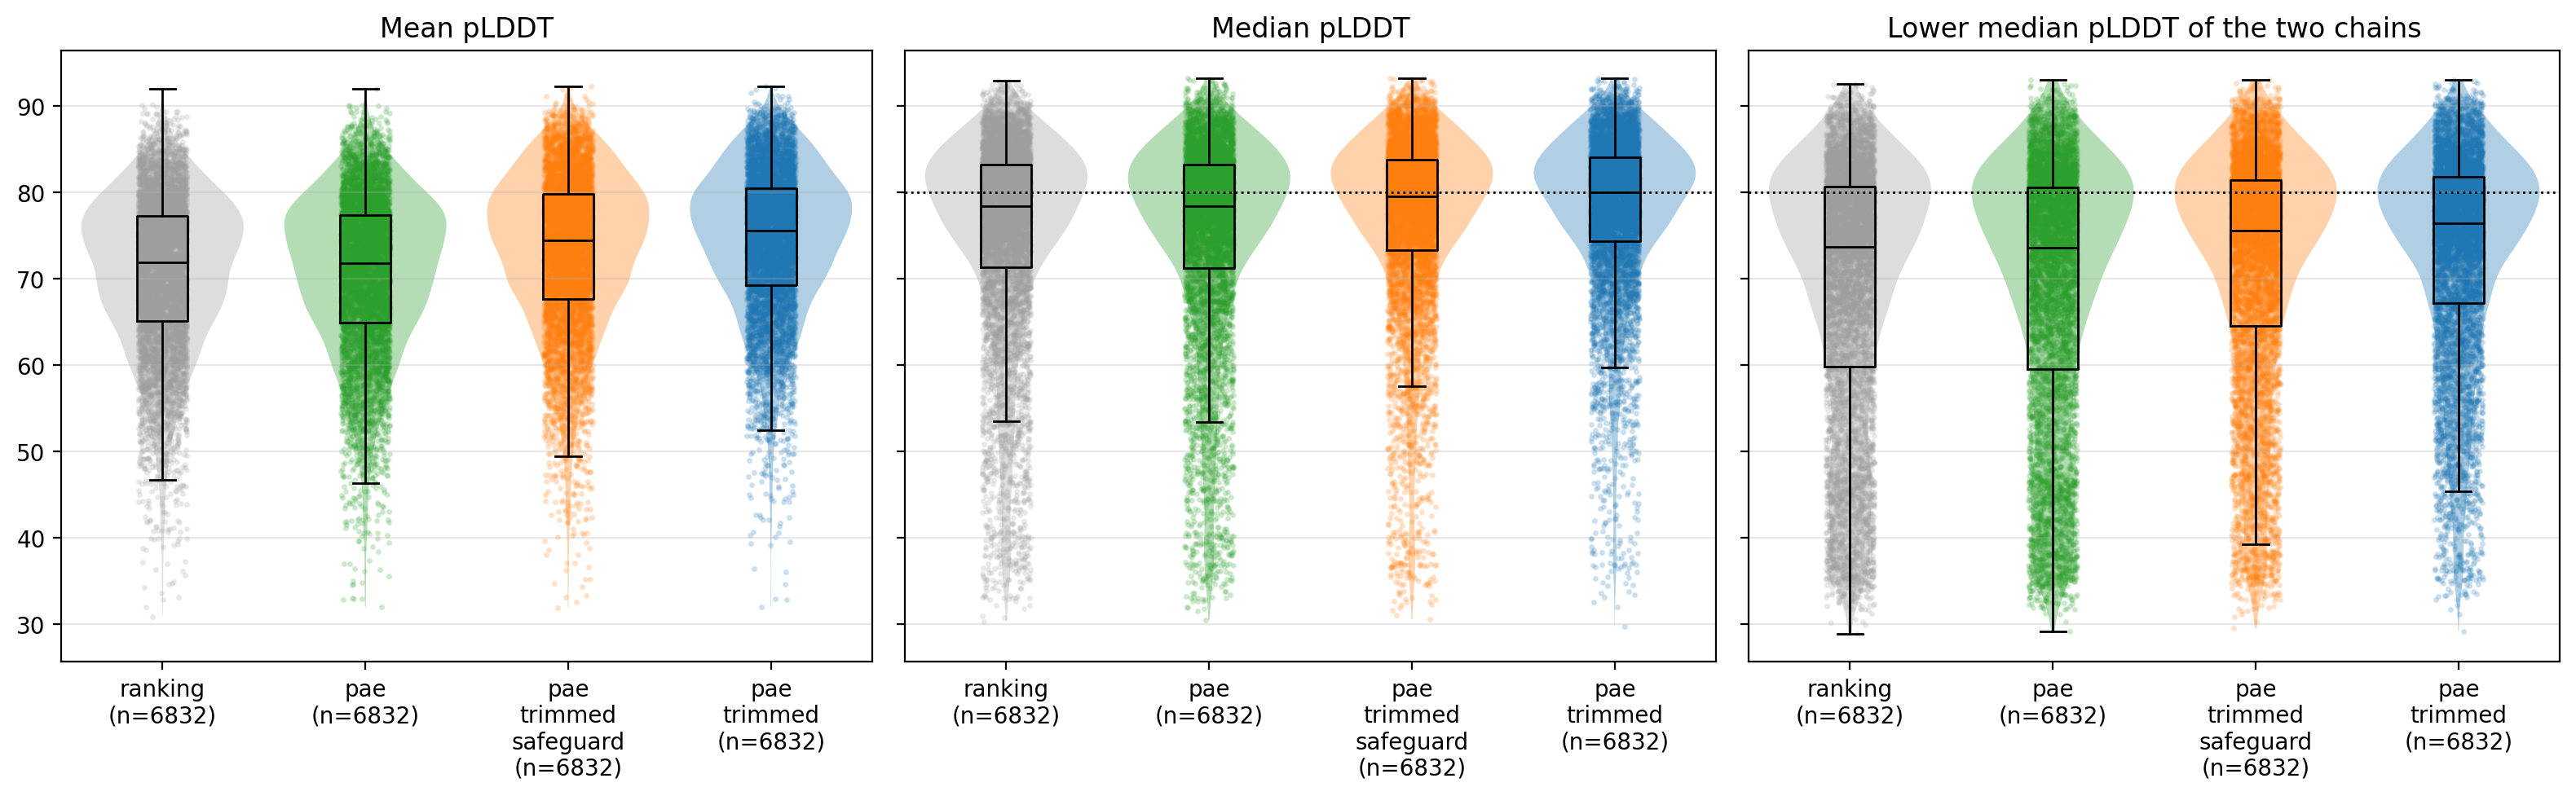

In [13]:
# %% distribution per set
fig, axes = plt.subplots(1, len(METRICS), figsize=(5.3 * len(METRICS), 5), sharey=True)
rng = np.random.default_rng(0)
for ax, (col, label) in zip(axes, METRICS):
    values_per_set = [plddt_per_pair.filter(pl.col("set") == s)[col].to_numpy() for s in PLOT_ORDER]
    violin_parts = ax.violinplot(values_per_set, showextrema=False, widths=0.8)
    for body, s in zip(violin_parts["bodies"], PLOT_ORDER):
        body.set_facecolor(COLORS[s]); body.set_alpha(0.35)
    ax.boxplot(values_per_set, widths=0.25, showfliers=False, medianprops=dict(color="k"))
    for i, (values, s) in enumerate(zip(values_per_set, PLOT_ORDER), start=1):
        ax.scatter(i + rng.uniform(-0.12, 0.12, len(values)), values, s=3, alpha=0.15, color=COLORS[s])
    if col in MEDIAN_METRICS:
        ax.axhline(CF_SUPERPOSITION_CUTOFF, color="k", ls=":", lw=1)
    ax.set_xticks(range(1, len(PLOT_ORDER) + 1),
                  [f"{s.replace('_', chr(10))}\n(n={len(v)})" for s, v in zip(PLOT_ORDER, values_per_set)])
    ax.set_title(label)
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

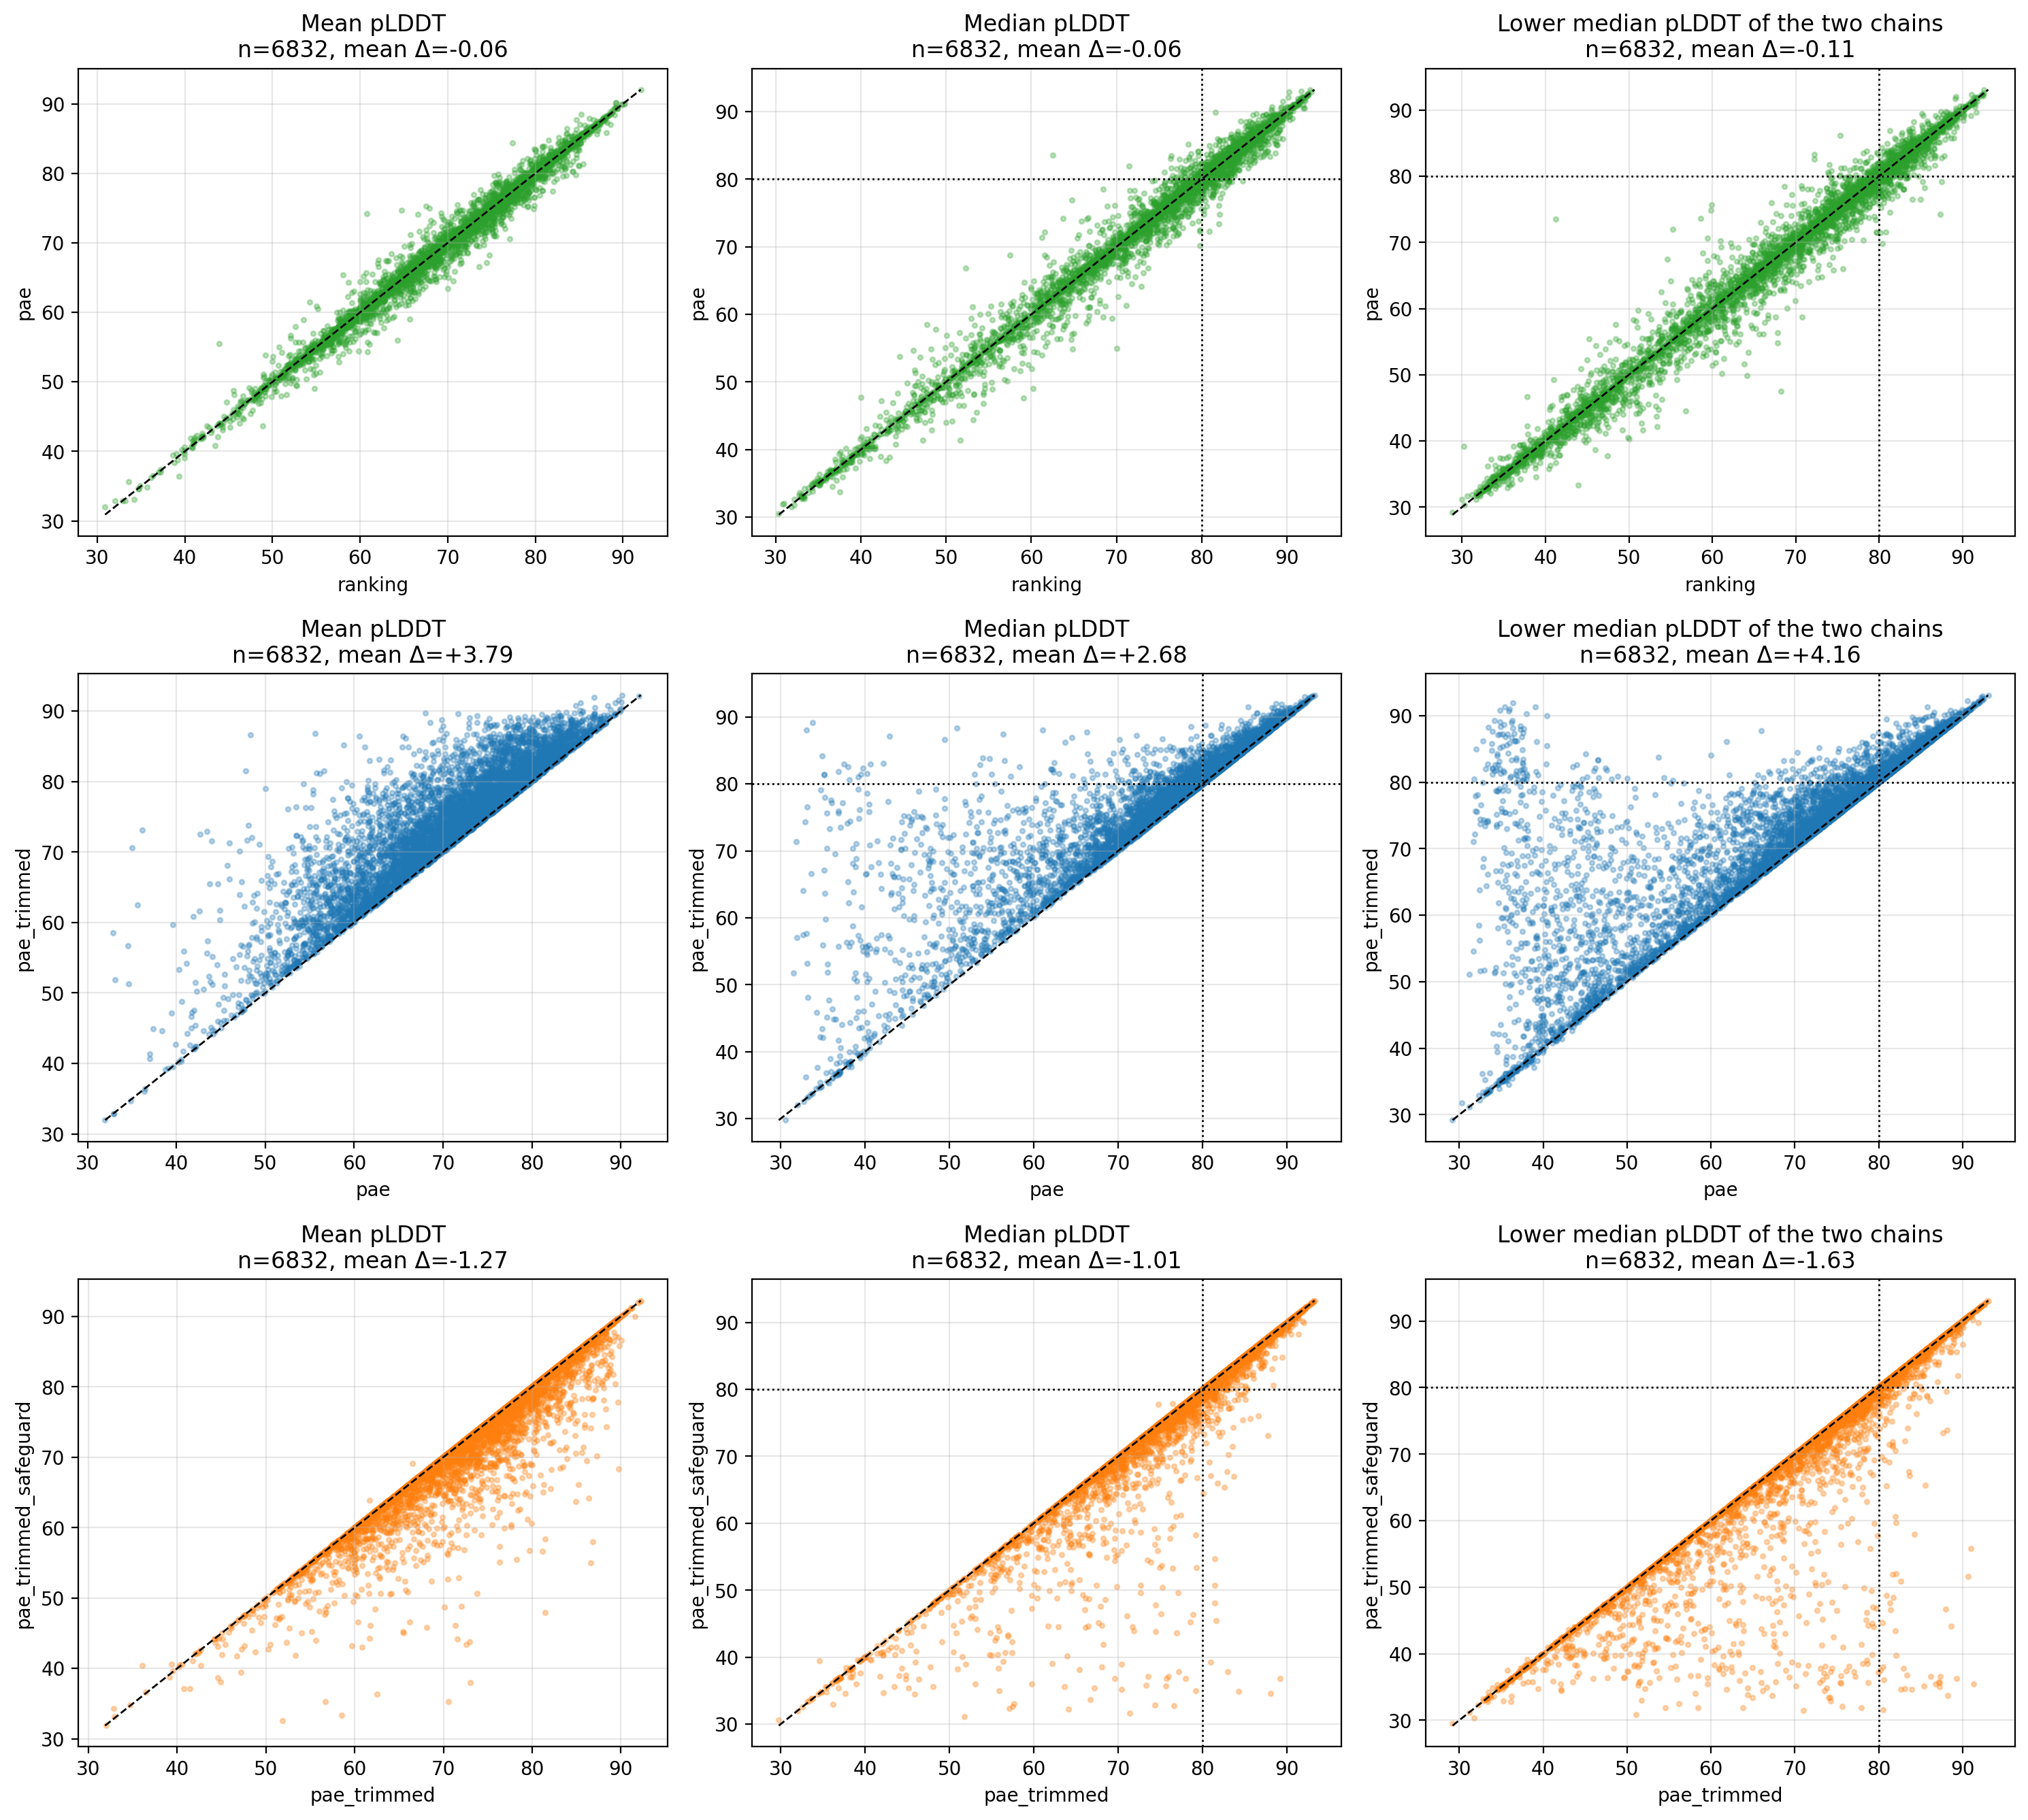

In [14]:
# %% paired comparison between consecutive pipeline steps
# below the diagonal = lower value in the later step
plddt_wide = plddt_per_pair.pivot(on="set", index="pair", values=[col for col, _ in METRICS])
consecutive_sets = list(zip(SETS[:-1], SETS[1:]))

fig, axes = plt.subplots(len(consecutive_sets), len(METRICS),
                         figsize=(5 * len(METRICS), 4.5 * len(consecutive_sets)))
for row, (set_before, set_after) in enumerate(consecutive_sets):
    for column, (col, label) in enumerate(METRICS):
        ax = axes[row, column]
        values_before = plddt_wide[f"{col}_{set_before}"].to_numpy()
        values_after = plddt_wide[f"{col}_{set_after}"].to_numpy()
        assert not (np.isnan(values_before).any() or np.isnan(values_after).any()), f"missing values for {col}"
        ax.scatter(values_before, values_after, s=6, alpha=0.3, color=COLORS[set_after])
        lowest, highest = min(values_before.min(), values_after.min()), max(values_before.max(), values_after.max())
        ax.plot([lowest, highest], [lowest, highest], "k--", lw=1)
        if col in MEDIAN_METRICS:
            ax.axhline(CF_SUPERPOSITION_CUTOFF, color="k", ls=":", lw=1)
            ax.axvline(CF_SUPERPOSITION_CUTOFF, color="k", ls=":", lw=1)
        ax.set_xlabel(set_before); ax.set_ylabel(set_after)
        ax.set_title(f"{label}\nn={len(values_before)}, mean Δ={np.mean(values_after - values_before):+.2f}")
        ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
# %% pairs whose lower chain median crosses the cutoff of 80 through trimming
cutoff_crossing = plddt_wide.select(
    pl.lit(len(common_pairs)).alias("n_pairs"),
    *[
        ((pl.col(f"min_chain_median_plddt_pae") < CF_SUPERPOSITION_CUTOFF)
         & (pl.col(f"min_chain_median_plddt_{s}") >= CF_SUPERPOSITION_CUTOFF)).sum().alias(f"lt80_to_ge80_{s}")
        for s in ["pae_trimmed", "pae_trimmed_safeguard"]
    ],
    *[
        (pl.col(f"min_chain_median_plddt_{s}") > pl.col("min_chain_median_plddt_pae")).sum().alias(f"median_raised_{s}")
        for s in ["pae_trimmed", "pae_trimmed_safeguard"]
    ],
)
cutoff_crossing

n_pairs,lt80_to_ge80_pae_trimmed,lt80_to_ge80_pae_trimmed_safeguard,median_raised_pae_trimmed,median_raised_pae_trimmed_safeguard
i32,u32,u32,u32,u32
6832,412,285,5731,5219


In [17]:
# %% CF superposition threshold per chain, before and after trimming
# AF2trans getTempPercentile: sorted pLDDT at index max(int(0.5*n - 1), 0), threshold = min(80, that value)
def cf_superposition_threshold(chain_plddt):
    sorted_plddt = np.sort(chain_plddt)
    percentile_index = max(int(0.5 * sorted_plddt.size - 1), 0)
    return min(float(CF_SUPERPOSITION_CUTOFF), float(sorted_plddt[percentile_index]))


def chain_superposition_stats(pdb_path):
    """Per chain of one pair model: n residues, CF threshold, n residues used for superposition."""
    with open(pdb_path, "rb") as pdb_file:
        ca_matches = CA_CHAIN_BFACTOR.findall(pdb_file.read())
    chain_ids = np.array([chain_id.decode() for chain_id, _ in ca_matches])
    ca_plddt = np.array([bfactor for _, bfactor in ca_matches]).astype(np.float64)
    assert np.unique(chain_ids).size == 2, f"expected 2 chains in {pdb_path}"
    stats_per_chain = []
    for chain_id in np.unique(chain_ids):
        chain_plddt = ca_plddt[chain_ids == chain_id]
        threshold = cf_superposition_threshold(chain_plddt)
        stats_per_chain.append((chain_id, chain_plddt.size, threshold, int((chain_plddt >= threshold).sum())))
    return stats_per_chain


SUPERPOSITION_SETS = ["pae", "pae_trimmed", "pae_trimmed_safeguard"]
superposition_jobs = [(s, pair, path) for s in SUPERPOSITION_SETS for pair, path in common_pdb_paths_by_set[s].items()]
with ProcessPoolExecutor(max_workers=32) as executor:
    stats_per_job = list(executor.map(chain_superposition_stats, (job[2] for job in superposition_jobs),
                                      chunksize=max(1, len(superposition_jobs) // 256)))

chain_superposition = pl.DataFrame(
    [(s, pair, *chain_stats) for (s, pair, _), job_stats in zip(superposition_jobs, stats_per_job)
     for chain_stats in job_stats],
    schema=["set", "pair", "chain", "n_res", "threshold", "n_superposition_res"], orient="row",
)
assert chain_superposition.height == 2 * len(SUPERPOSITION_SETS) * len(common_pairs)

untrimmed_chains = chain_superposition.filter(pl.col("set") == "pae").drop("set")
trimmed_vs_untrimmed = pl.concat([
    untrimmed_chains.join(chain_superposition.filter(pl.col("set") == s).drop("set"),
                          on=["pair", "chain"], how="inner", suffix="_trimmed").with_columns(pl.lit(s).alias("trimming"))
    for s in ["pae_trimmed", "pae_trimmed_safeguard"]
])
assert trimmed_vs_untrimmed.height == 2 * 2 * len(common_pairs), "chain IDs differ between untrimmed and trimmed models"

trimmed_vs_untrimmed = trimmed_vs_untrimmed.with_columns(
    (pl.col("threshold_trimmed") != pl.col("threshold")).alias("threshold_changed"),
    (1 - pl.col("n_superposition_res_trimmed") / pl.col("n_superposition_res")).alias("frac_superposition_res_lost"),
)

In [20]:
# %% summary: per chain and per pair (a transformation can change if either chain's threshold changed)
pair_threshold_change = trimmed_vs_untrimmed.group_by("trimming", "pair").agg(
    pl.col("threshold_changed").any().alias("any_chain_threshold_changed"),
    (pl.col("threshold") < CF_SUPERPOSITION_CUTOFF).any().alias("any_chain_below_80_untrimmed"),
)
pair_threshold_summary = pair_threshold_change.group_by("trimming").agg(
    pl.len().alias("n_pairs"),
    pl.col("any_chain_below_80_untrimmed").mean().alias("frac_pairs_below_80_untrimmed"),
    pl.col("any_chain_threshold_changed").mean().alias("frac_pairs_threshold_changed"),
)
chain_loss_summary = trimmed_vs_untrimmed.filter(pl.col("threshold_changed")).group_by("trimming").agg(
    pl.len().alias("n_changed_chains"),
    pl.col("frac_superposition_res_lost").median().alias("median_frac_superposition_res_lost"),
    pl.col("frac_superposition_res_lost").quantile(0.9).alias("q90_frac_superposition_res_lost"),
)
pair_threshold_summary.join(chain_loss_summary, on="trimming")

trimming,n_pairs,frac_pairs_below_80_untrimmed,frac_pairs_threshold_changed,n_changed_chains,median_frac_superposition_res_lost,q90_frac_superposition_res_lost
str,u32,f64,f64,u32,f64,f64
"""pae_trimmed""",6832,0.726581,0.669496,6538,0.101124,0.368421
"""pae_trimmed_safeguard""",6832,0.726581,0.628806,5878,0.066617,0.254237


In [18]:
# %% complex -> benchmark / novel, pair -> group
pdb_mapping_path = data_dir / "complete_complex_pdb_mapping_v2/all_pdb_matches_with_match_class.csv"
pdb_mapping = pl.read_csv(pdb_mapping_path)
assert pdb_mapping["complex_ac"].is_unique().all(), "complex_ac not unique in mapping"

MATCH_CLASS_TO_GROUP = {
    "exact_pdb_match":     "benchmark",
    "no_homology_match":   "novel",
    "no_sufficient_match": "novel",
}
GROUPS = ["benchmark", "novel"]
complex_group = pdb_mapping.select(
    "complex_ac",
    pl.col("match_class").replace_strict(MATCH_CLASS_TO_GROUP, default=None).alias("group"),
)

pool_pairs_path = PIPE / "18_CP_model_based_on_pae/18_CP_model_based_on_pae_pool_pairs_metrics.csv"
pair_complex = pl.read_csv(pool_pairs_path, columns=["complex_ac", "pair"]).unique()
complexes_not_in_mapping = set(pair_complex["complex_ac"]) - set(pdb_mapping["complex_ac"])
assert not complexes_not_in_mapping, f"complexes missing in pdb mapping: {sorted(complexes_not_in_mapping)[:5]}"
pairs_not_in_pool_file = common_pairs - set(pair_complex["pair"])
assert not pairs_not_in_pool_file, f"{len(pairs_not_in_pool_file)} common pairs not in pool file"

pair_group = (
    pair_complex.join(complex_group, on="complex_ac", how="inner")
    .group_by("pair").agg(pl.col("group").unique().alias("groups"))
)
assert not pair_group["groups"].list.contains(None).any(), \
    "some pairs belong to a complex whose match_class is not in MATCH_CLASS_TO_GROUP"
pair_group = pair_group.with_columns(
    pl.when(pl.col("groups").list.len() == 1).then(pl.col("groups").list.first())
    .otherwise(pl.lit("both")).alias("group")
).select("pair", "group")
print(pair_group["group"].value_counts().sort("group"))

plddt_per_pair_grouped = plddt_per_pair.join(pair_group.filter(pl.col("group") != "both"), on="pair", how="inner")
assert plddt_per_pair_grouped.height > 0

shape: (3, 2)
┌───────────┬───────┐
│ group     ┆ count │
│ ---       ┆ ---   │
│ str       ┆ u32   │
╞═══════════╪═══════╡
│ benchmark ┆ 1855  │
│ both      ┆ 181   │
│ novel     ┆ 4803  │
└───────────┴───────┘


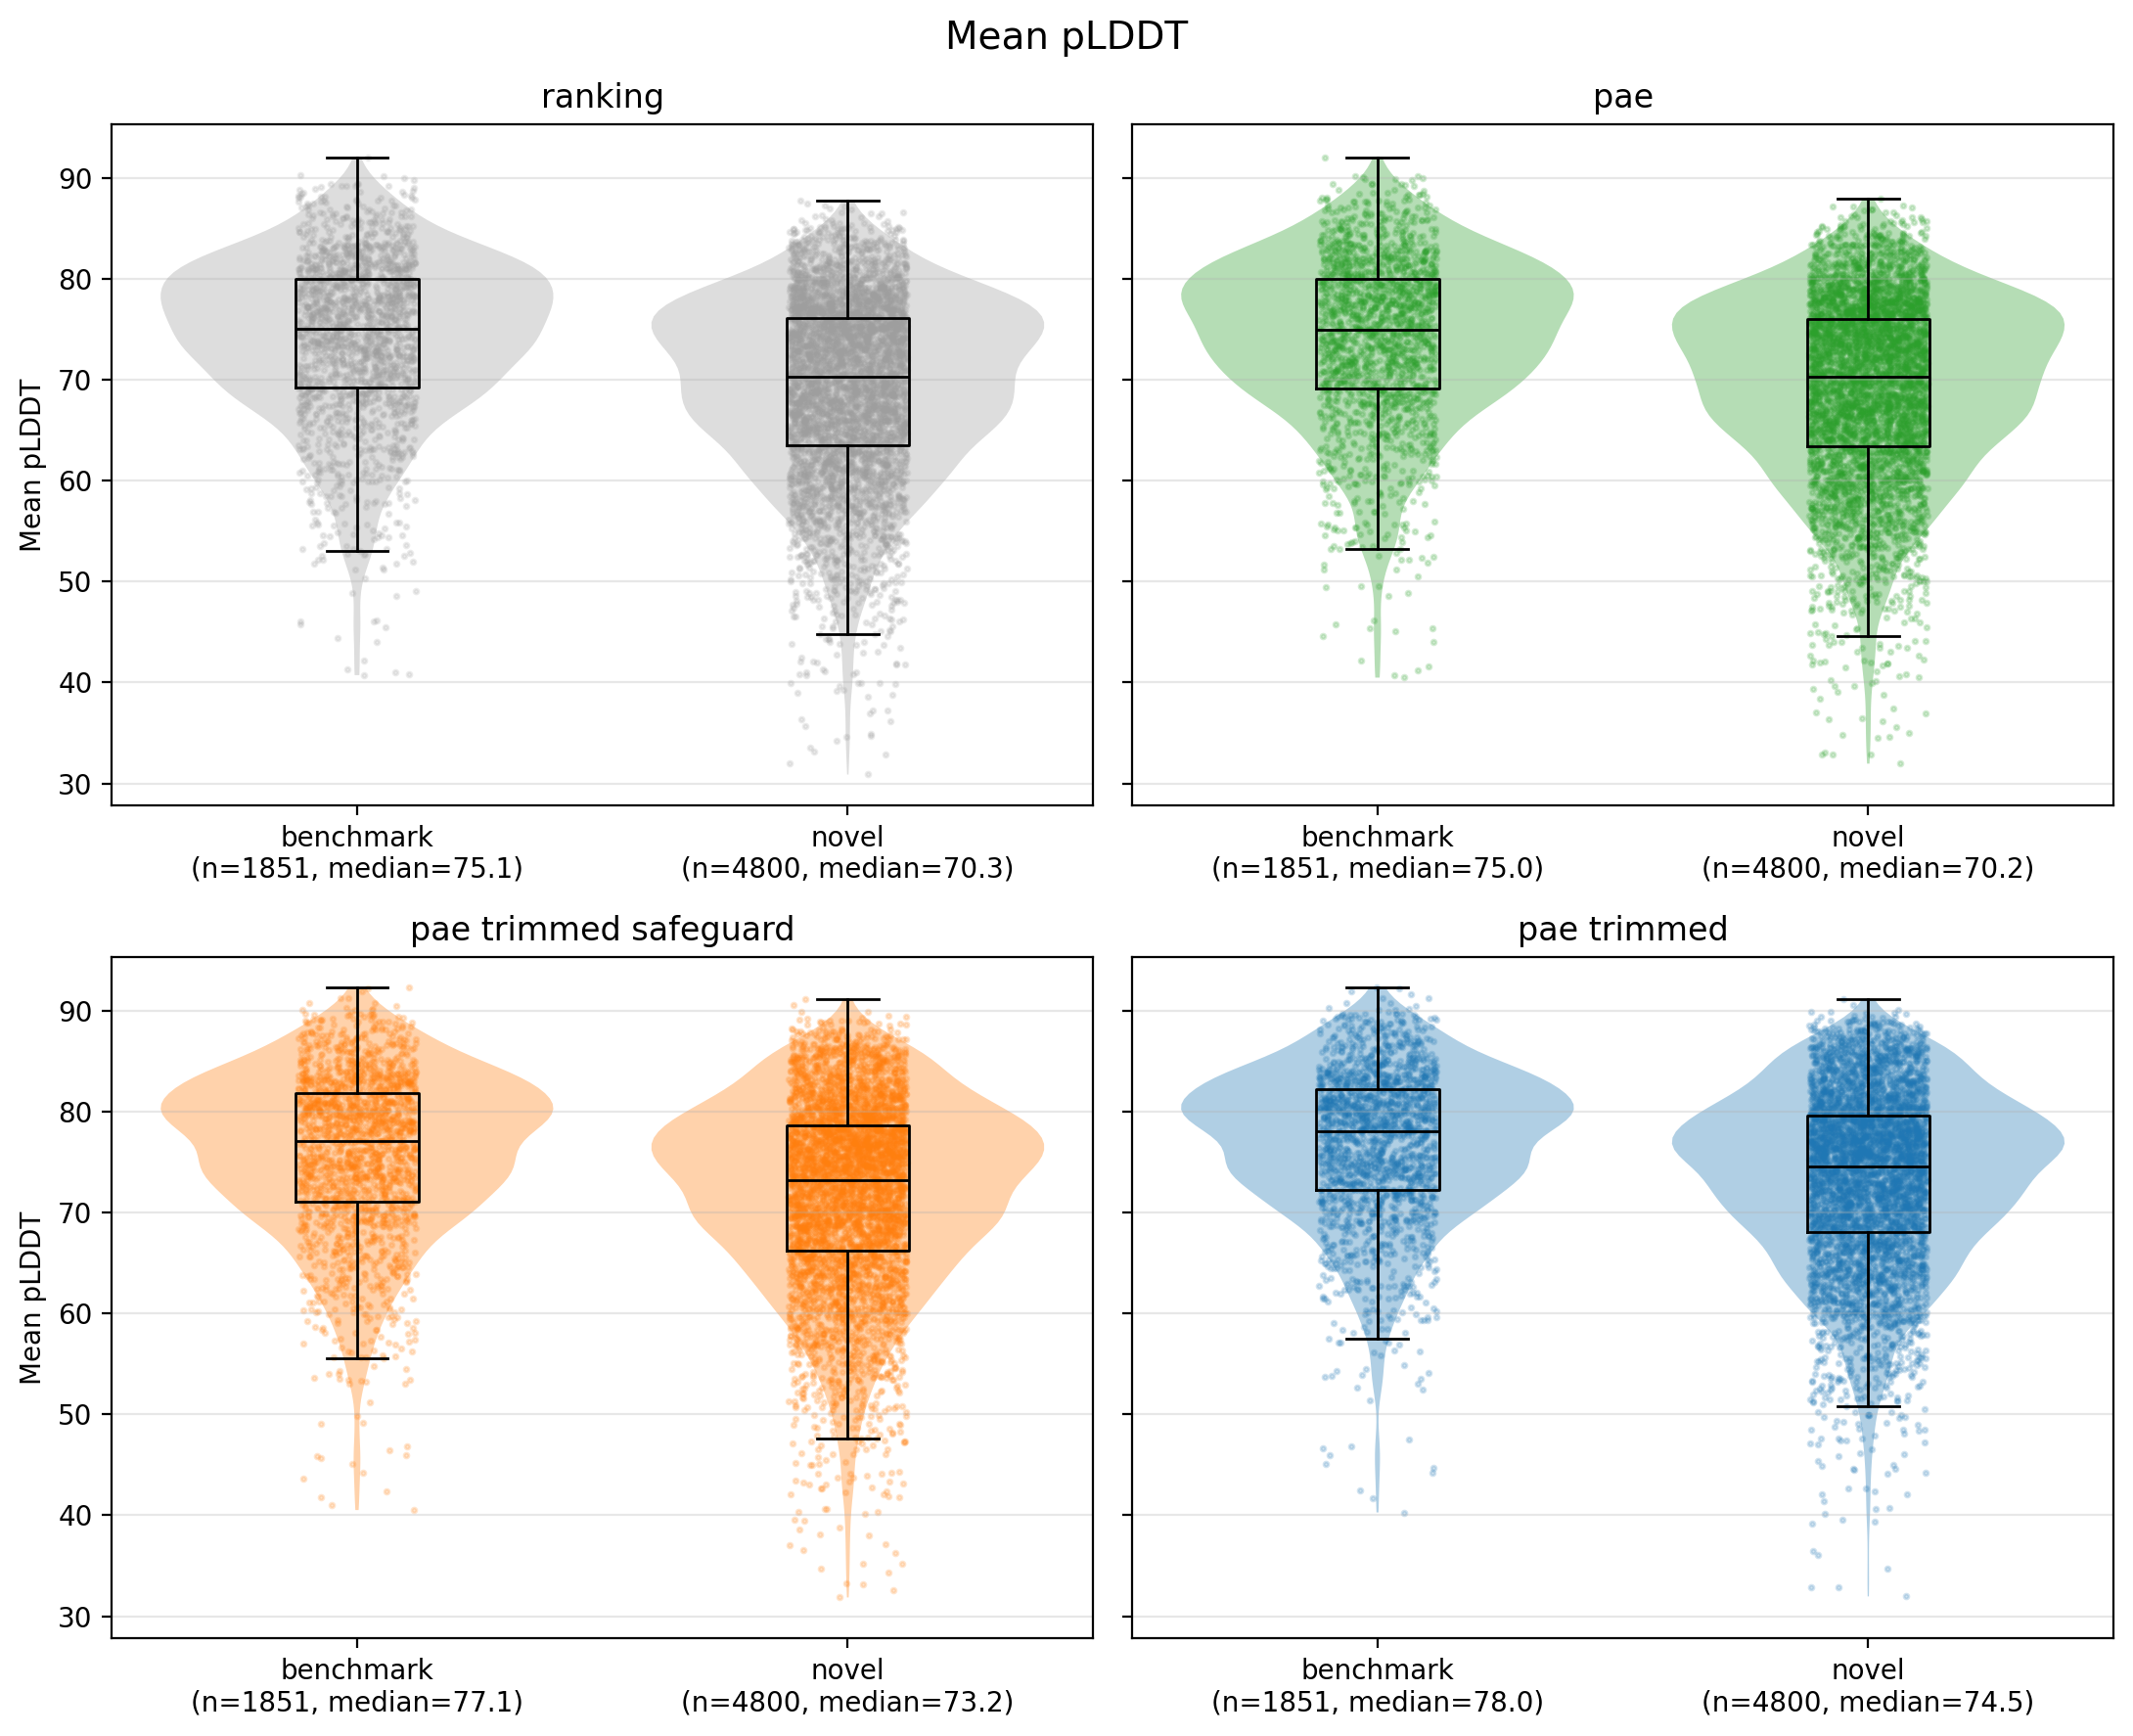

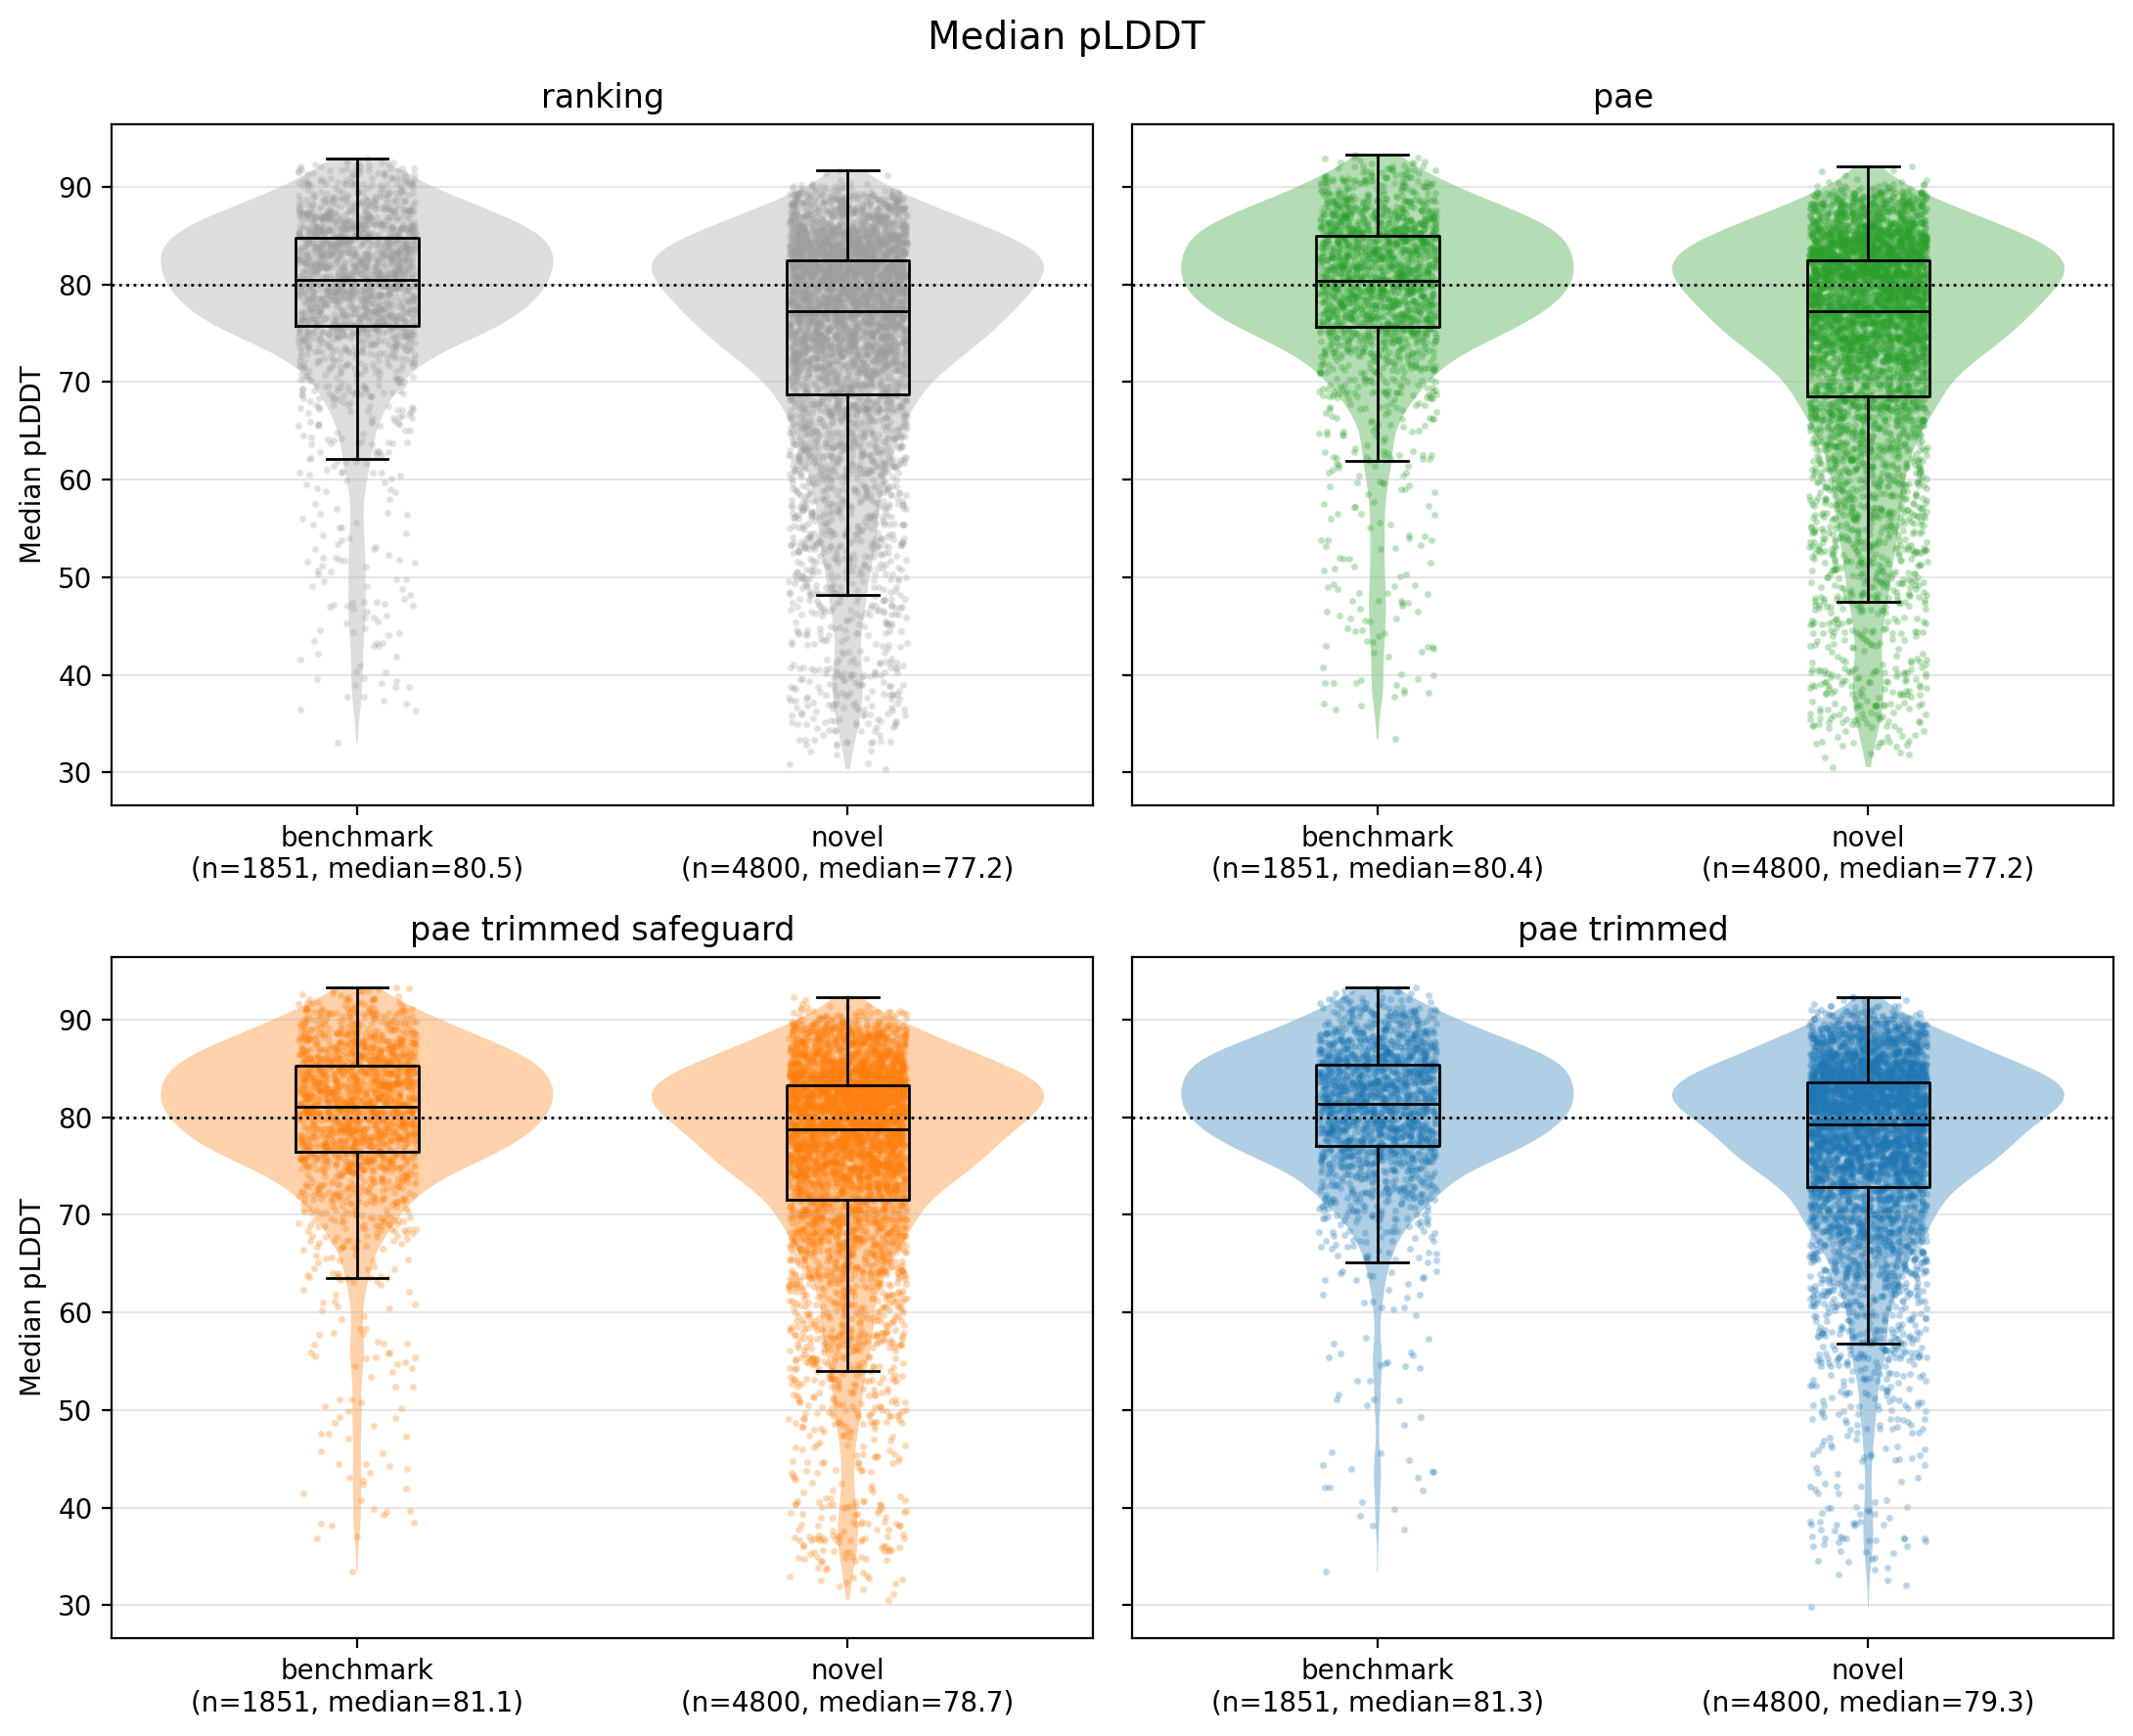

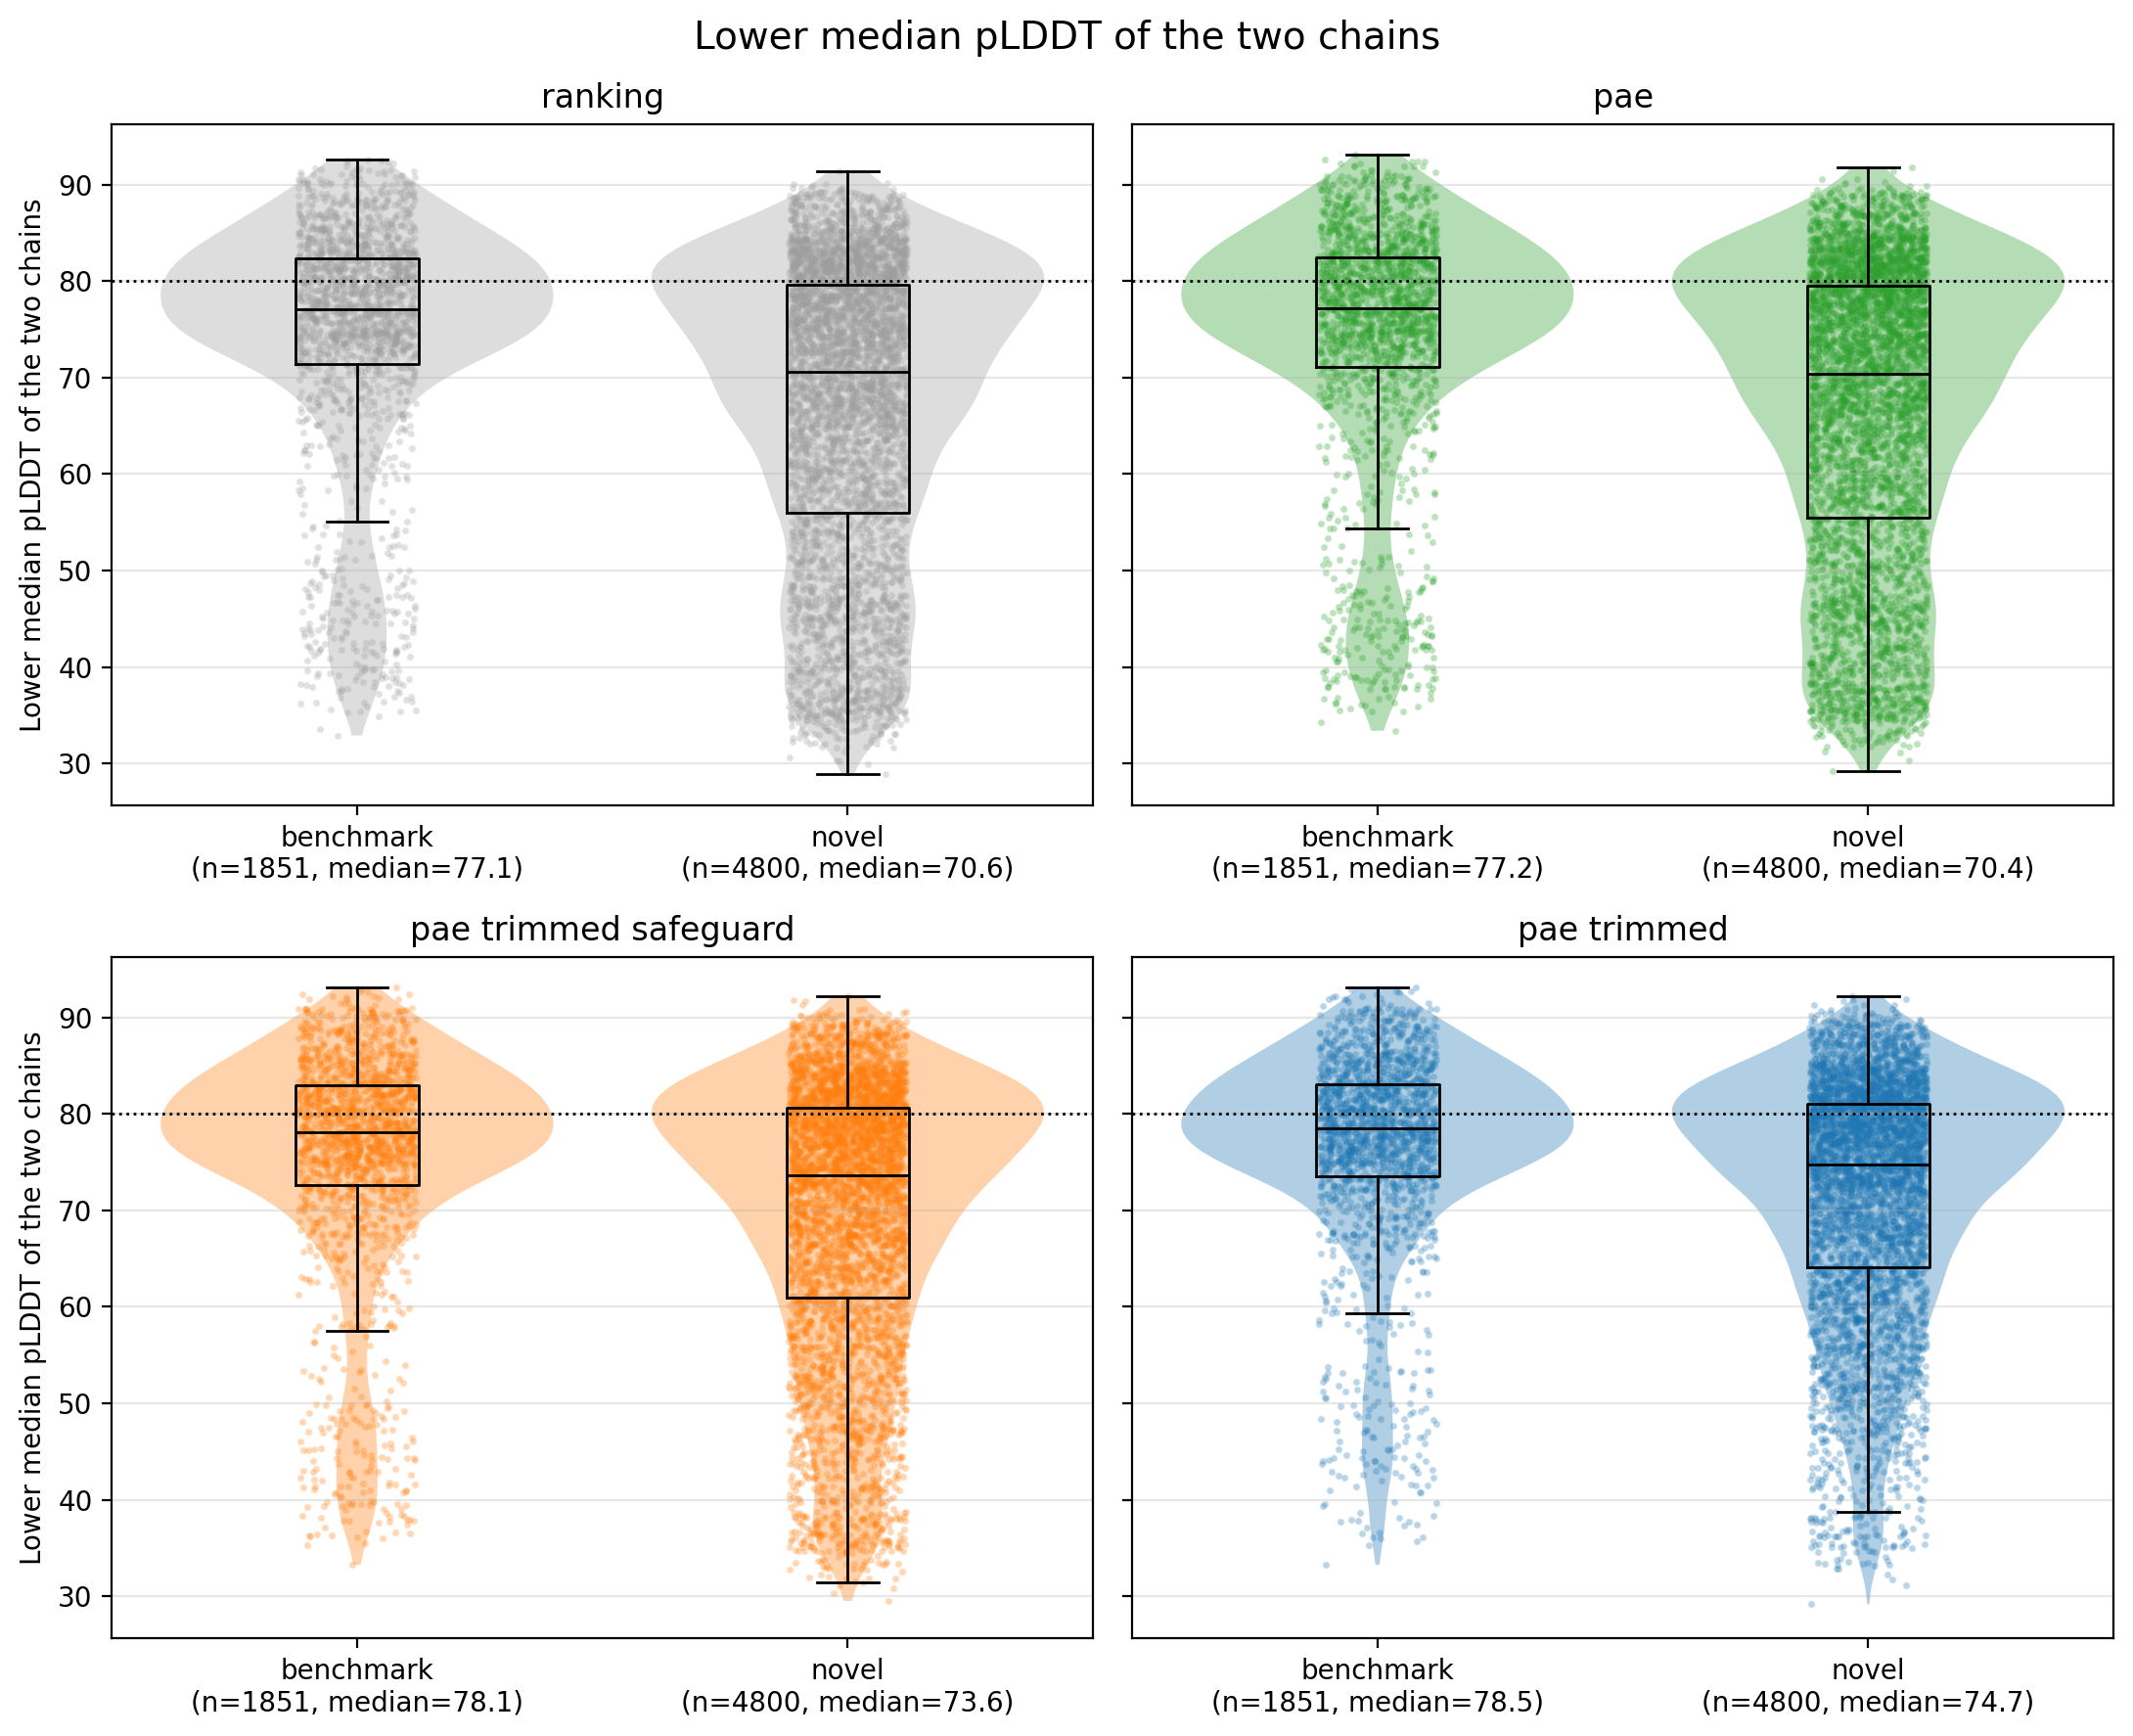

In [19]:
# %% benchmark vs novel, one figure per metric, one panel per set
def plot_benchmark_vs_novel(plddt_grouped, col, label):
    fig, axes = plt.subplots(2, 2, figsize=(11, 9), sharey=True)
    rng = np.random.default_rng(0)
    for ax, s in zip(axes.flat, PLOT_ORDER):
        plddt_set = plddt_grouped.filter(pl.col("set") == s)
        values_per_group = [plddt_set.filter(pl.col("group") == g)[col].to_numpy() for g in GROUPS]
        assert all(len(v) > 0 for v in values_per_group), f"empty group in {s}"
        violin_parts = ax.violinplot(values_per_group, showextrema=False, widths=0.8)
        for body in violin_parts["bodies"]:
            body.set_facecolor(COLORS[s]); body.set_alpha(0.35)
        ax.boxplot(values_per_group, widths=0.25, showfliers=False, medianprops=dict(color="k"))
        for i, values in enumerate(values_per_group, start=1):
            ax.scatter(i + rng.uniform(-0.12, 0.12, len(values)), values, s=3, alpha=0.2, color=COLORS[s])
        if col in MEDIAN_METRICS:
            ax.axhline(CF_SUPERPOSITION_CUTOFF, color="k", ls=":", lw=1)
        ax.set_xticks([1, 2], [f"{g}\n(n={len(v)}, median={np.median(v):.1f})"
                               for g, v in zip(GROUPS, values_per_group)])
        ax.set_title(s.replace("_", " "))
        ax.grid(axis="y", alpha=0.3)
    for ax in axes[:, 0]:
        ax.set_ylabel(label)
    fig.suptitle(label, fontsize=14)
    plt.tight_layout()
    plt.show()


for col, label in METRICS:
    plot_benchmark_vs_novel(plddt_per_pair_grouped, col, label)

In [21]:
# %% share of pairs where trimming can change the transformation (lower chain median < 80)
# approximation with np.median; CF uses the lower median and the other chain is ignored
trimming_effect_on_superposition = plddt_wide.select(
    pl.len().alias("n_pairs"),
    (pl.col("min_chain_median_plddt_pae") < CF_SUPERPOSITION_CUTOFF).sum().alias("n_below_80_untrimmed"),
    *[
        ((pl.col("min_chain_median_plddt_pae") < CF_SUPERPOSITION_CUTOFF)
         & (pl.col(f"min_chain_median_plddt_{s}") > pl.col("min_chain_median_plddt_pae"))).sum()
        .alias(f"n_threshold_raised_{s}")
        for s in ["pae_trimmed", "pae_trimmed_safeguard"]
    ],
)
trimming_effect_on_superposition

n_pairs,n_below_80_untrimmed,n_threshold_raised_pae_trimmed,n_threshold_raised_pae_trimmed_safeguard
u32,u32,u32,u32
6832,4940,4424,4033
